# PZ data challenge: official test-set results

The organisers scored our subtask 1 p(z) files against the hidden test redshifts and returned the results in
`znn_moments_results/`. We do not get the true redshifts, only these summaries, per configuration
(4 task sets × 2 sims × 2 depths):

| file | content |
|---|---|
| `*_point.yaml` | bias (`mean`), scatter (`std`), 3σ-clipped (`outlier_rate`) and \|Δz\| > 0.2 (`abs_outlier_rate`) outlier rates of Δz = (zmode − z)/(1 + z). Rounded to 4 decimals. |
| `*_pit_qq.yaml` | PIT KS, CvM, Anderson–Darling (`ksamp`) statistics and PIT outlier rate |
| `*_pit_prob.yaml` | the PIT density (qp's spline) at 101 points on [0, 1] |
| `*_point_v_redshift.yaml` | Δz statistics in bins of **true** z (15 bins on [0, 3], empty bins dropped): biweight bias ± error, σ, 3σ outlier rate, and the 2.5/16/50/84/97.5 % quantiles |
| `*_point_v_mag.yaml` | the same in bins of true i-band magnitude |

Everything can be redrawn in the paper's style except the per-object z_phot vs z_true scatter (only the
organisers' PNG has it). The binned quantiles of Δz vs true z stand in for it below.

For comparison the organisers' BPZ run (`bpz_136temps_4tasks`, 136 templates) was scored in the same way; its files are in
`results_bpz_official/bpz_136temps_4tasks/` with the same names and format. BPZ is drawn in dark grey throughout.

Note that the challenge always scores against `redshift`, also for task sets 3 and 4 (no `redshift_manyband`).

In [8]:
import itertools
import os
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

from pz_data_challenge import scoring

RESULTS_DIR = "znn_moments_results"  # as returned by the organisers
BPZ_DIR = "results_bpz_official/bpz_136temps_4tasks"  # the organisers' BPZ baseline, same file format
PLOT_DIR = "plots"
PREFIX = "official"  # figures and tables are saved as plots/official_<name>.{pdf,tex}
os.makedirs(PLOT_DIR, exist_ok=True)

TASKSETS = [1, 2, 3, 4]
SIMS = ["cardinal", "flagship"]
SCENARIOS = ["1yr", "10yr"]
CONFIGS = list(itertools.product(TASKSETS, SIMS, SCENARIOS))
COLUMNS = list(itertools.product(SIMS, SCENARIOS))  # one panel column per sim and depth

# same style as pz_challenge_results.ipynb
TASKSET_CMAPS = {1: "Blues", 2: "Greens", 3: "Oranges", 4: "Purples"}
COLORS = {t: plt.get_cmap(cmap)(0.7) for t, cmap in TASKSET_CMAPS.items()}
BPZ_COLOR = "0.3"  # dark grey, for BPZ in every figure
SIM_LABELS = {"cardinal": "Cardinal", "flagship": "Flagship"}
DEPTH_LABELS = {"1yr": "Y1", "10yr": "Y10"}


def label(sim, scenario):
    return f"{SIM_LABELS[sim]} {DEPTH_LABELS[scenario]}"


def save(fig, name):
    fig.savefig(os.path.join(PLOT_DIR, f"{PREFIX}_{name}.pdf"), bbox_inches="tight")


def save_latex(dfs, name, columns, caption):
    # In the style of main.tex (MNRAS, no booktabs): \hline at the top, under the header, between task sets and at the
    # bottom. Task set, sim and depth share one label column ("T1 Cardinal Y1"). `dfs` maps a method name to its scores
    # table; with more than one method each gets its own block of `columns`, under a spanning header, in a table*.
    def fmt(v):
        return f"{v:.1f}" if abs(v) >= 10 else f"{v:.4f}"

    methods = list(dfs)
    first = dfs[methods[0]]
    env = "table*" if len(methods) > 1 else "table"
    lines = [
        rf"\begin{{{env}}}",
        rf"\caption{{{caption}}}",
        rf"\label{{tab:{name}}}",
        r"\begin{tabular}{l" + "r" * len(columns) * len(methods) + "}",
        r"\hline",
    ]
    if len(methods) > 1:
        lines.append(" & ".join(["", *(rf"\multicolumn{{{len(columns)}}}{{c}}{{{m}}}" for m in methods)]) + r" \\")
    lines += [
        " & ".join(["Configuration", *(list(columns.values()) * len(methods))]) + r" \\",
        r"\hline",
    ]
    for _, group in first.groupby(level="taskset", sort=False):
        for config in group.index:
            taskset, sim, scenario = config
            cells = [f"T{taskset} {SIM_LABELS[sim]} {DEPTH_LABELS[scenario]}"]
            cells += [fmt(float(dfs[m].loc[config, k])) for m in methods for k in columns]
            lines.append(" & ".join(cells) + r" \\")
        lines.append(r"\hline")
    lines += [r"\end{tabular}", rf"\end{{{env}}}"]
    tex = "\n".join(lines) + "\n"
    with open(os.path.join(PLOT_DIR, f"{PREFIX}_{name}.tex"), "w") as f:
        f.write(tex)
    print(tex)


## Load the results into tables

In [9]:
def read(taskset, sim, scenario, kind, results_dir=RESULTS_DIR):
    with open(os.path.join(results_dir, f"taskset_{taskset}_{sim}_{scenario}_{kind}.yaml")) as f:
        return yaml.safe_load(f)


def score_table(results_dir):
    # one row per configuration: the scalar scores
    df = pd.DataFrame({c: read(*c, "point", results_dir) | read(*c, "pit_qq", results_dir) for c in CONFIGS}).T
    df.index.names = ["taskset", "sim", "scenario"]
    return df


def long_table(kind, x_key, results_dir=RESULTS_DIR):
    # Stack the per-configuration curves into one long table with the configuration as index columns.
    frames = []
    for c in CONFIGS:
        d = pd.DataFrame(read(*c, kind, results_dir)).rename(columns={x_key: "x"})
        frames.append(d.assign(taskset=c[0], sim=c[1], scenario=c[2]))
    return pd.concat(frames, ignore_index=True)


scores = score_table(RESULTS_DIR)
pit = long_table("pit_prob", "x_vals").rename(columns={"y_vals": "pdf"})
vs_z = long_table("point_v_redshift", "z_mean")
vs_mag = long_table("point_v_mag", "mag_mean")

# the same for BPZ
bpz_scores = score_table(BPZ_DIR)
bpz_pit = long_table("pit_prob", "x_vals", BPZ_DIR).rename(columns={"y_vals": "pdf"})
bpz_vs_z = long_table("point_v_redshift", "z_mean", BPZ_DIR)
bpz_vs_mag = long_table("point_v_mag", "mag_mean", BPZ_DIR)

# keep a copy in plain CSV, which is easy to reuse elsewhere
for name, df in dict(scores=scores.reset_index(), pit=pit, vs_z=vs_z, vs_mag=vs_mag).items():
    df.to_csv(os.path.join(RESULTS_DIR, f"tidy_{name}.csv"), index=False)

SCORE_KEYS = ["mean", "std", "outlier_rate", "abs_outlier_rate", "ks", "CvM", "ksamp", "outlier"]
pd.concat({"ZNN": scores[SCORE_KEYS], "BPZ": bpz_scores[SCORE_KEYS]}, axis=1)


ZNN                                        \
                             mean     std outlier_rate abs_outlier_rate   
taskset sim      scenario                                                 
1       cardinal 1yr      -0.0003  0.0167       0.0306           0.0009   
                 10yr      0.0000  0.0104       0.0222           0.0000   
        flagship 1yr      -0.0006  0.0181       0.0314           0.0015   
                 10yr      0.0002  0.0109       0.0246           0.0000   
2       cardinal 1yr      -0.0023  0.0540       0.1287           0.0984   
                 10yr     -0.0016  0.0322       0.1145           0.0436   
        flagship 1yr      -0.0036  0.0563       0.1285           0.1040   
                 10yr     -0.0029  0.0289       0.0986           0.0316   
3       cardinal 1yr      -0.0016  0.0572       0.0898           0.0696   
                 10yr     -0.0032  0.0376       0.0586           0.0184   
        flagship 1yr      -0.0043  0.0607       0.0848           0.0728   
                 10yr     -0.0081  0.0320       0.0676           0.0130   
4       cardinal 1yr      -0.0016  0.0575       0.0940           0.0728   
                 10yr     -0.0060  0.0330       0.0810           0.0250   
        flagship 1yr      -0.0100  0.0740       0.1101           0.1275   
                 10yr     -0.0088  0.0378       0.0740           0.0278   

                                                                        \
                                 ks         CvM        ksamp   outlier   
taskset sim      scenario                                                
1       cardinal 1yr       0.017572    1.749651     9.105229  0.000000   
                 10yr      0.013434    0.961507     7.958176  0.000000   
        flagship 1yr       0.020349    1.848430     5.417659  0.000000   
                 10yr      0.026823    3.596638    13.171829  0.000000   
2       cardinal 1yr       0.139362  184.002174  1006.944806  0.000405   
                 10yr      0.135598  179.299674   950.932304  0.000102   
        flagship 1yr       0.163594  204.655645  1062.507116 -0.000002   
                 10yr      0.146840  194.192985   998.329955 -0.002344   
3       cardinal 1yr       0.064252   24.983380    90.360627  0.000000   
                 10yr      0.059728   21.288903   116.044006  0.000000   
        flagship 1yr       0.049644   16.166790    72.421744  0.000049   
                 10yr      0.112032   95.912508   384.105964  0.000000   
4       cardinal 1yr       0.037764   11.152303    41.567554  0.000000   
                 10yr      0.083649   60.567868   252.636483  0.000000   
        flagship 1yr       0.053542   22.322436    78.151899  0.005717   
                 10yr      0.084482   56.910419   234.337107  0.002670   

                              BPZ                                        \
                             mean     std outlier_rate abs_outlier_rate   
taskset sim      scenario                                                 
1       cardinal 1yr       0.0039  0.0371       0.0744           0.0335   
                 10yr     -0.0072  0.0313       0.0498           0.0072   
        flagship 1yr      -0.0014  0.0238       0.0358           0.0032   
                 10yr     -0.0021  0.0191       0.0270           0.0000   
2       cardinal 1yr       0.0008  0.1159       0.0680           0.1792   
                 10yr     -0.0088  0.0500       0.0826           0.0570   
        flagship 1yr      -0.0022  0.0512       0.1233           0.0905   
                 10yr     -0.0016  0.0307       0.0722           0.0215   
3       cardinal 1yr       0.0009  0.1137       0.0744           0.1792   
                 10yr     -0.0096  0.0495       0.0842           0.0576   
        flagship 1yr      -0.0029  0.0520       0.1146           0.0830   
                 10yr     -0.0022  0.0309       0.0660           0.0190   
4       cardinal 1yr       0.0014  0.1130       0.0808           0.1832 

## Scores table (test set)

Bias, scatter, |Δz| > 0.2 outlier fraction and PIT KS for ZNN, then the same four for BPZ as extra columns, with task set, sim and depth in one label column. With eight number columns it no longer fits one MNRAS column, so it is a `table*`.

In [10]:
save_latex(
    {"ZNN": scores, "BPZ": bpz_scores},
    "pz_metrics",
    {
        "mean": r"bias",
        "std": r"$\sigma$",
        "abs_outlier_rate": r"$f_\mathrm{out}$",
        "ks": r"KS",
    },
    r"Official challenge scores on the test set. Point estimates: bias, scatter $\sigma$ and fraction of outliers "
    r"with $|\Delta z| > 0.2$, $f_\mathrm{out}$, of $\Delta z = (z_\mathrm{mode} - z)/(1 + z)$. Calibration: KS statistic of the PIT against uniform. "
    r"Left: ZNN; right: the challenge's BPZ baseline. T: task set; Y1, Y10: LSST depth after one and ten years.",
)

\begin{table*}
\caption{Official challenge scores on the test set. Point estimates: bias, scatter $\sigma$ and fraction of outliers with $|\Delta z| > 0.2$, $f_\mathrm{out}$, of $\Delta z = (z_\mathrm{mode} - z)/(1 + z)$. Calibration: KS statistic of the PIT against uniform. Left: ZNN; right: the challenge's BPZ baseline. T: task set; Y1, Y10: LSST depth after one and ten years.}
\label{tab:pz_metrics}
\begin{tabular}{lrrrrrrrr}
\hline
 & \multicolumn{4}{c}{ZNN} & \multicolumn{4}{c}{BPZ} \\
Configuration & bias & $\sigma$ & $f_\mathrm{out}$ & KS & bias & $\sigma$ & $f_\mathrm{out}$ & KS \\
\hline
T1 Cardinal Y1 & -0.0003 & 0.0167 & 0.0009 & 0.0176 & 0.0039 & 0.0371 & 0.0335 & 0.0685 \\
T1 Cardinal Y10 & 0.0000 & 0.0104 & 0.0000 & 0.0134 & -0.0072 & 0.0313 & 0.0072 & 0.1598 \\
T1 Flagship Y1 & -0.0006 & 0.0181 & 0.0015 & 0.0203 & -0.0014 & 0.0238 & 0.0032 & 0.1996 \\
T1 Flagship Y10 & 0.0002 & 0.0109 & 0.0000 & 0.0268 & -0.0021 & 0.0191 & 0.0000 & 0.2370 \\
\hline
T2 Cardinal Y1 & -0.00

## Challenge points

The scores graded against the challenge tiers (`scoring.metric_dict`): one point per nested range a metric falls inside, at most 3 per metric.

In [11]:
def challenge_points(df):
    pts = pd.DataFrame(
        {c: {k: sum(lo <= float(v[k]) <= hi for lo, hi in r) for k, r in scoring.metric_dict.items()} for c, v in df.iterrows()}
    ).T
    pts.index.names = df.index.names
    pts["total"] = pts.sum(axis=1)
    return pts


points = challenge_points(scores)
bpz_points = challenge_points(bpz_scores)
N_MAX = sum(len(r) for r in scoring.metric_dict.values())
print(f"points per configuration (out of {N_MAX}):")
display(pd.concat({"ZNN": points, "BPZ": bpz_points}, axis=1))
print(f"total per task set (out of {4 * N_MAX}):")
print(pd.DataFrame({m: p["total"].groupby(level="taskset").sum() for m, p in [("ZNN", points), ("BPZ", bpz_points)]}).to_string())


points per configuration (out of 21):


ZNN                                            \
                          mean std abs_outlier_rate CvM outlier ks ksamp   
taskset sim      scenario                                                  
1       cardinal 1yr         3   3                3   3       3  3     3   
                 10yr        3   3                3   3       3  3     3   
        flagship 1yr         3   3                3   3       3  3     3   
                 10yr        3   3                3   3       3  3     3   
2       cardinal 1yr         3   1                2   3       3  3     2   
                 10yr        3   2                2   3       3  3     3   
        flagship 1yr         3   1                1   3       3  3     2   
                 10yr        3   2                2   3       3  3     3   
3       cardinal 1yr         3   1                2   3       3  3     3   
                 10yr        3   2                3   3       3  3     3   
        flagship 1yr         3   1                2   3       3  3     3   
                 10yr        3   2                3   3       3  3     3   
4       cardinal 1yr         3   1                2   3       3  3     3   
                 10yr        3   2                3   3       3  3     3   
        flagship 1yr         3   1                1   3       3  3     3   
                 10yr        3   2                2   3       3  3     3   

                                 BPZ                                      \
                          total mean std abs_outlier_rate CvM outlier ks   
taskset sim      scenario                                                  
1       cardinal 1yr         21    3   2                2   3       3  3   
                 10yr        21    3   2                3   3       3  3   
        flagship 1yr         21    3   3                3   2       3  3   
                 10yr        21    3   3                3   2       3  2   
2       cardinal 1yr         17    3   0                1   3       3  3   
                 10yr        19    3   2                2   3       3  3   
        flagship 1yr         16    3   1                2   3       3  3   
                 10yr        19    3   2                3   3       3  3   
3       cardinal 1yr         18    3   0                1   3       3  3   
                 10yr        20    3   2                2   2       3  3   
        flagship 1yr         18    3   1                2   3       3  3   
                 10yr        20    3   2                3   3       3  3   
4       cardinal 1yr         18    3   0                1   3       3  3   
                 10yr        20    3   2                2   2       3  3   
        flagship 1yr         17    3   1                1   3       3  3   
                 10yr        19    3   2                2   3       3  3   

                                       
                          ksamp total  
taskset sim      scenario              
1       cardinal 1yr          3    19  
                 10yr         3    20  
        flagship 1yr          2    19  
                 10yr         1    17  
2       cardinal 1yr          3    16  
                 10yr         3    19  
        flagship 1yr          3    18  
                 10yr         3    20  
3       cardinal 1yr          3    16  
                 10yr         2    17  
        flagship 1yr          3    18  
                 10yr         3    20  
4       cardinal 1yr          3    16  
                 10yr         2    17  
        flagship 1yr          3    17  
                 10yr         3    19

total per task set (out of 84):
         ZNN  BPZ
taskset          
1         84   75
2         71   73
3         76   71
4         74   69


## PIT

The PIT density returned by the challenge, ZNN filled and BPZ as the grey line. The y range is set by ZNN and the BPZ interior, so BPZ's spikes at PIT = 0 and 1 run off the top of the panels (the KS values in each panel are unaffected). A flat line at 1 means the p(z) are calibrated, a U shape means they are too narrow, and a hump means they are too wide.

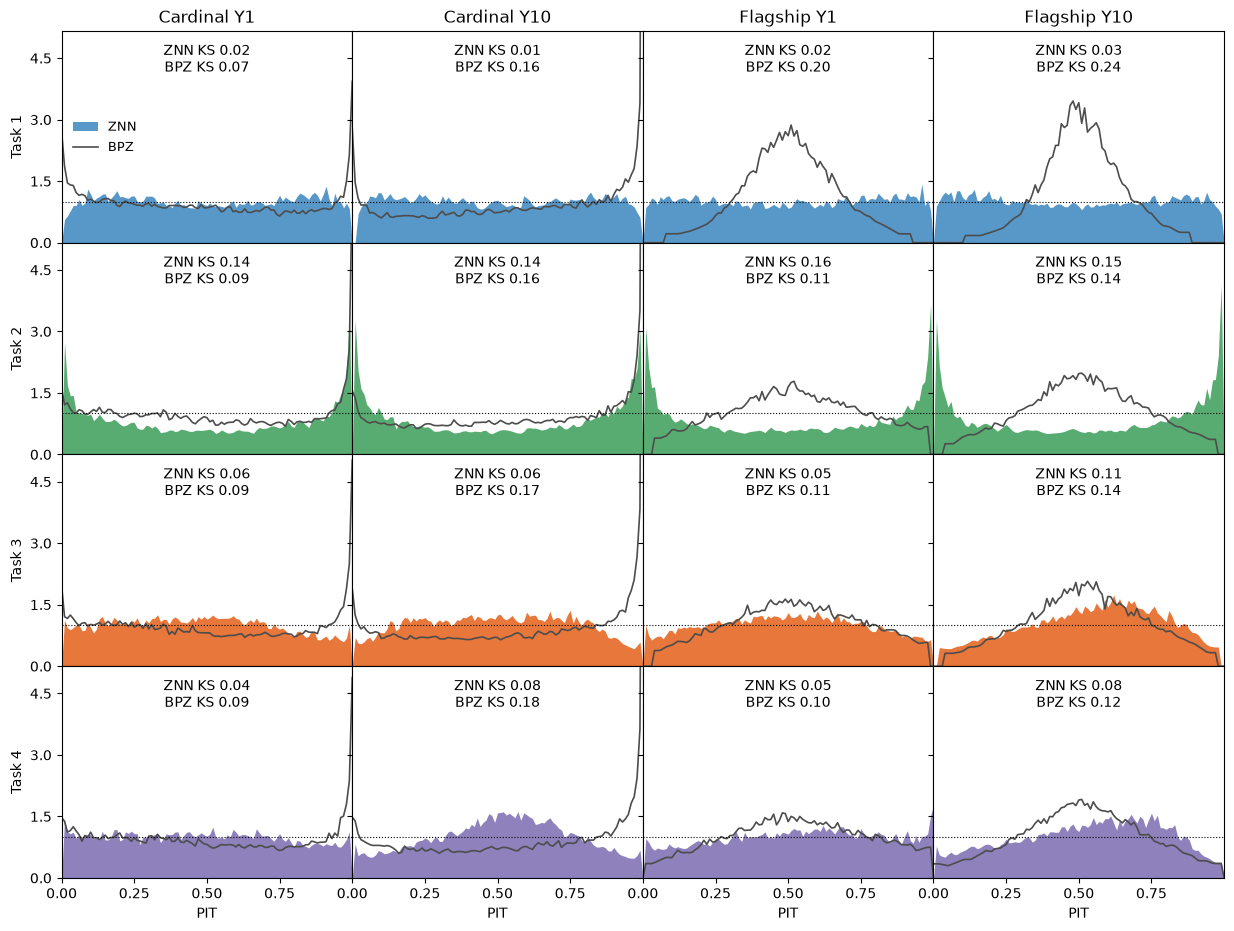

In [12]:
from matplotlib.ticker import MaxNLocator

fig, axes = plt.subplots(4, 4, figsize=(15, 11), sharex=True, sharey=True, gridspec_kw=dict(hspace=0, wspace=0))
top = 0
for row, taskset in enumerate(TASKSETS):
    for col, (sim, scenario) in enumerate(COLUMNS):
        ax = axes[row, col]
        p = pit.query("taskset == @taskset and sim == @sim and scenario == @scenario")
        b = bpz_pit.query("taskset == @taskset and sim == @sim and scenario == @scenario")
        ax.fill_between(p["x"], p["pdf"], color=COLORS[taskset], alpha=0.8, lw=0, label="ZNN")
        ax.plot(b["x"], b["pdf"], color=BPZ_COLOR, lw=1.2, label="BPZ")
        ax.axhline(1, color="k", lw=0.8, ls=":")
        ks = scores.loc[(taskset, sim, scenario), "ks"]
        ks_bpz = bpz_scores.loc[(taskset, sim, scenario), "ks"]
        ax.text(0.5, 0.95, f"ZNN KS {ks:.2f}\nBPZ KS {ks_bpz:.2f}", transform=ax.transAxes, ha="center", va="top", linespacing=1.2, fontsize=10,
                bbox=dict(fc="white", ec="none", alpha=0.8, pad=1))
        interior = b["pdf"][(b["x"] > 0.05) & (b["x"] < 0.95)]
        top = max(top, p["pdf"].max(), interior.max())  # BPZ's spikes at PIT = 0, 1 run off the top
        if row == 0:
            ax.set_title(label(sim, scenario), fontsize=12)
        if col == 0:
            ax.set_ylabel(f"Task {taskset}")
        if row == 3:
            ax.set_xlabel("PIT")
axes[0, 0].set_xlim(0, 1)
axes[0, 0].set_ylim(0, 1.25 * top)
axes[0, 0].set_xticks([0, 0.25, 0.5, 0.75])
axes[0, 0].yaxis.set_major_locator(MaxNLocator(nbins=4, prune="upper"))
axes[0, 0].legend(loc="center left", fontsize=9, frameon=False)
save(fig, "pit")
plt.show()

## Δz against true redshift

This replaces the z_phot vs z_true scatter: the median of Δz = (zmode − z)/(1 + z) in bins of true z, with the
68 % interval as error bars. ZNN is coloured, BPZ dark grey and shifted slightly to the right
so the two do not overlap. The dashed lines mark the |Δz| = 0.2 outlier threshold.


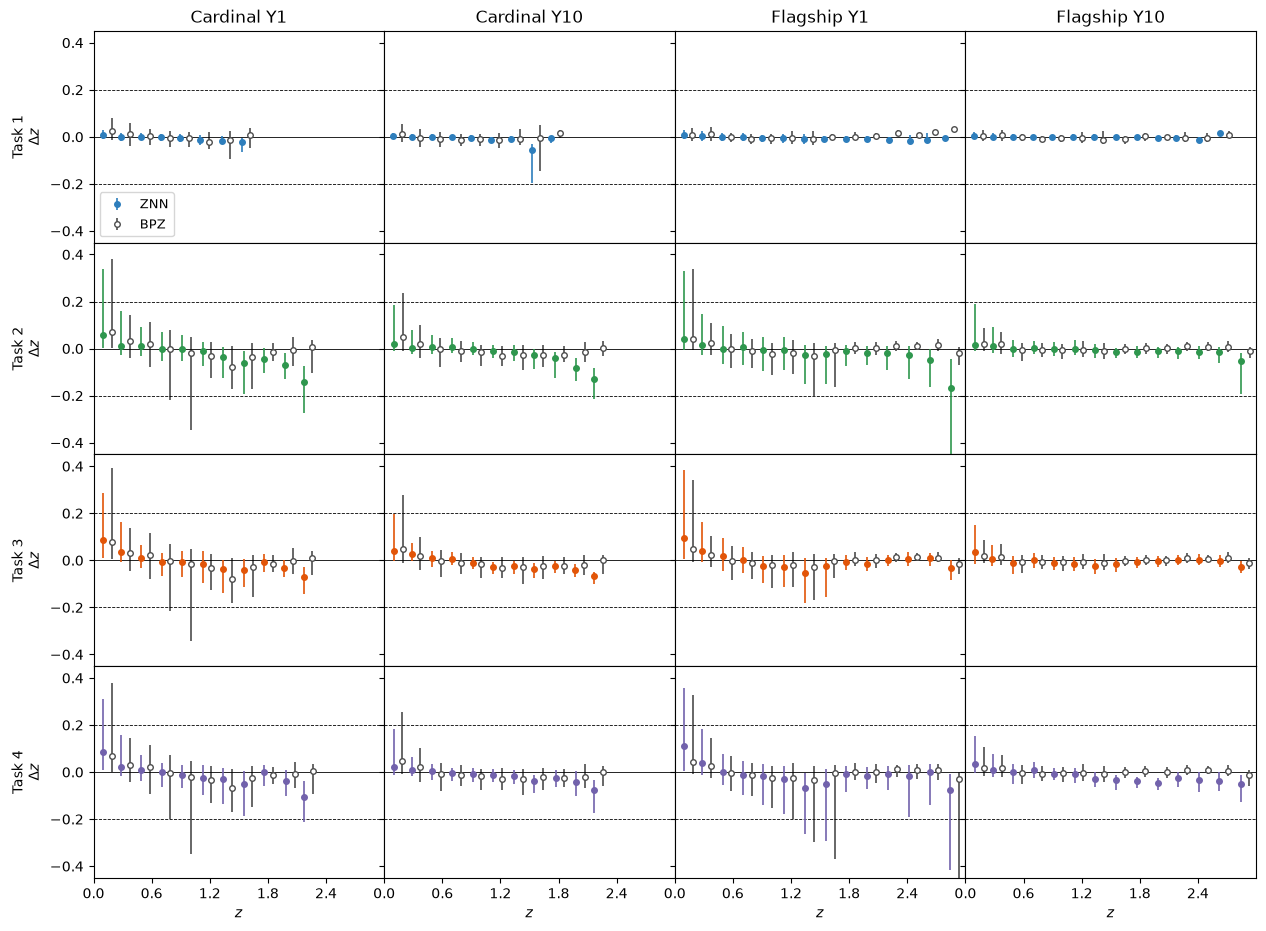

In [16]:
def quantile_grid(df, bpz_df, xlabel, xlim, name, offset):
    fig, axes = plt.subplots(4, 4, figsize=(15, 11), sharex=True, sharey=True, gridspec_kw=dict(hspace=0, wspace=0))
    for row, taskset in enumerate(TASKSETS):
        for col, (sim, scenario) in enumerate(COLUMNS):
            ax = axes[row, col]
            for d, color, shift, method, z in [
                (df, COLORS[taskset], -offset, "ZNN", 3),
                (bpz_df, BPZ_COLOR, offset, "BPZ", 2),
            ]:
                d = d.query("taskset == @taskset and sim == @sim and scenario == @scenario").dropna(subset=["median"])
                x = d["x"] + shift
                err = [d["median"] - d["qt_68_low"], d["qt_68_high"] - d["median"]]
                ax.errorbar(x, d["median"], err, fmt="o", color=color, mfc="white" if method == "BPZ" else color, mew=1.0, ms=4, elinewidth=1.2, capsize=0, label=method,
                            zorder=z)
            ax.axhline(0, color="k", lw=0.6)
            for s in (-0.2, 0.2):
                ax.axhline(s, color="k", lw=0.6, ls="--")
            if row == 0:
                ax.set_title(label(sim, scenario), fontsize=12)
            if col == 0:
                ax.set_ylabel(f"Task {taskset}\n$\\Delta z$")
            if row == 3:
                ax.set_xlabel(xlabel)
    axes[0, 0].set_xlim(*xlim)
    axes[0, 0].xaxis.set_major_locator(MaxNLocator(nbins=5, prune="upper"))  # keep labels off the panel joins
    axes[0, 0].set_ylim(-0.45, 0.45)
    axes[0, 0].legend(loc="lower left", fontsize=9)
    save(fig, name)
    plt.show()


quantile_grid(vs_z, bpz_vs_z, "$z$", (0, 3), "dz_vs_z", offset=0.045)

## Bias, scatter and outliers against true redshift and magnitude

One column per sim and depth, one line per task set. Bias is the biweight mean of Δz with its error, σ the
biweight scale and the outlier rate the 3σ-clipped one, all per bin.

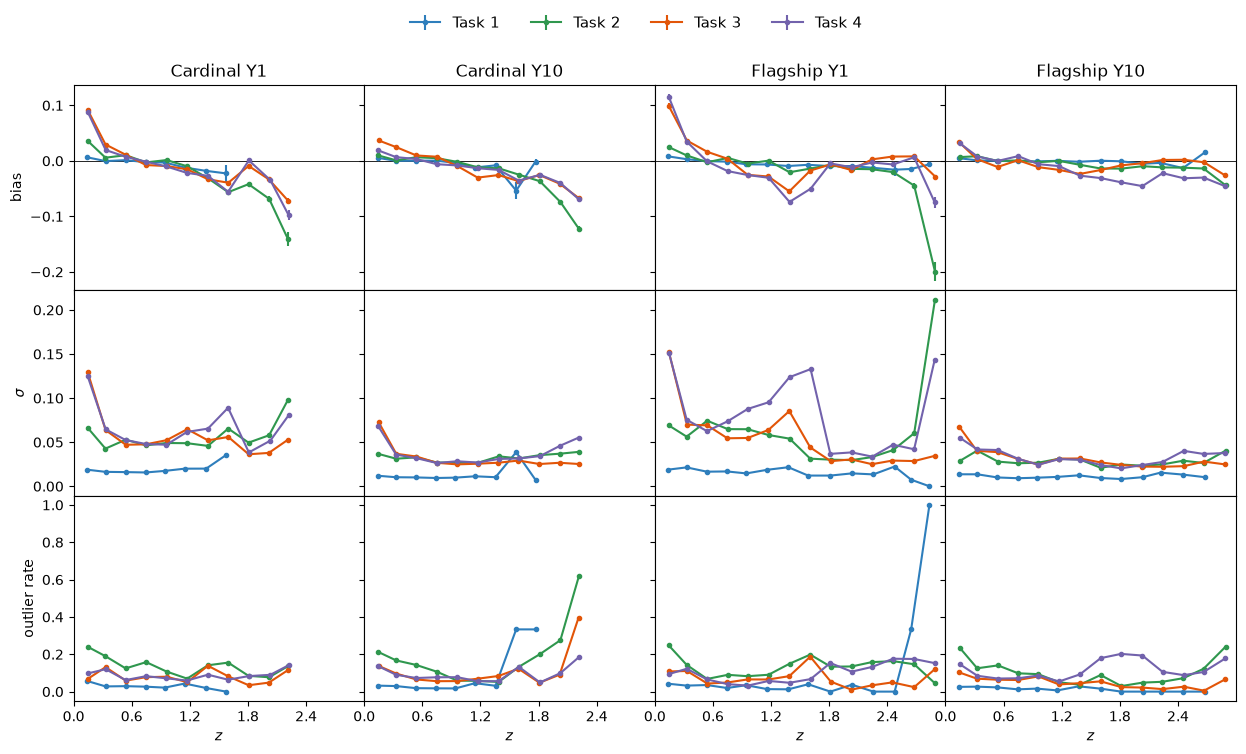

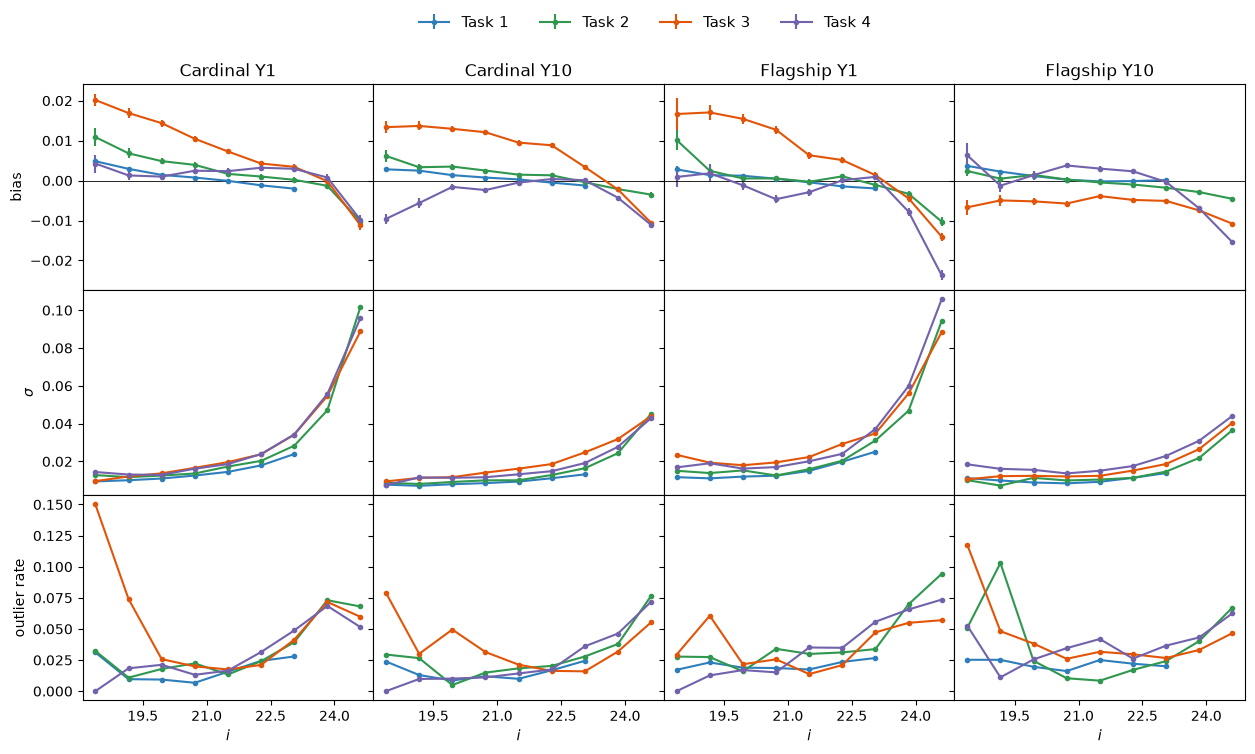

In [14]:
def stats_grid(df, xlabel, xlim, name):
    rows = [
        ("biweight_mean", "bias"),
        ("biweight_sigma", r"$\sigma$"),
        ("biweight_outlier", "outlier rate"),
    ]
    fig, axes = plt.subplots(3, 4, figsize=(15, 8), sharex=True, sharey="row", gridspec_kw=dict(hspace=0, wspace=0))
    for col, (sim, scenario) in enumerate(COLUMNS):
        for taskset in TASKSETS:
            d = df.query("taskset == @taskset and sim == @sim and scenario == @scenario")
            kw = dict(color=COLORS[taskset], lw=1.5, marker=".", label=f"Task {taskset}")
            axes[0, col].errorbar(d["x"], d["biweight_mean"], d["biweight_std"], **kw)
            axes[1, col].plot(d["x"], d["biweight_sigma"], **kw)
            axes[2, col].plot(d["x"], d["biweight_outlier"], **kw)
        axes[0, col].axhline(0, color="k", lw=0.6)
        axes[0, col].set_title(label(sim, scenario), fontsize=12)
        axes[2, col].set_xlabel(xlabel)
    for ax, (_, ylabel) in zip(axes[:, 0], rows):
        ax.set_ylabel(ylabel)
    axes[0, 0].set_xlim(*xlim)
    axes[0, 0].xaxis.set_major_locator(MaxNLocator(nbins=5, prune="upper"))  # keep labels off the panel joins
    # one row of task sets above the column titles
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 0.93), ncol=len(TASKSETS), frameon=False,
               fontsize=11)
    save(fig, name)
    plt.show()


stats_grid(vs_z, "$z$", (0, 3), "stats_vs_z")
stats_grid(vs_mag, "$i$", (vs_mag["x"].min() - 0.3, vs_mag["x"].max() + 0.3), "stats_vs_mag")